# Encoder-decoder sequence reversal

Reverse a four-symbol input one symbol at a time. A small encoder reads the whole source, while the decoder attends to the encoded source and its own prefix.

All outputs here have a fixed known length of four. Training supplies the correct preceding symbol. During greedy evaluation, the decoder receives its own previous prediction. The test set contains unseen source strings.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


from itertools import product


def split_sequences(vocab, width, n_train):
    seq = torch.tensor(list(product(range(vocab), repeat=width)), dtype=torch.long)
    order = torch.randperm(len(seq), generator=torch.Generator().manual_seed(73))
    return seq[order[:n_train]], seq[order[n_train:]]


class Transducer(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(6, 32)
        self.src_pos = nn.Parameter(torch.randn(4, 32) * 0.3)
        self.tgt_pos = nn.Parameter(torch.randn(4, 32) * 0.3)
        self.net = nn.Transformer(
            32,
            4,
            num_encoder_layers=1,
            num_decoder_layers=1,
            dim_feedforward=72,
            dropout=0.0,
            batch_first=True,
        )
        self.out = nn.Linear(32, 5)

    def forward(self, source, prefix):
        n = prefix.shape[1]
        mask = torch.ones(n, n, dtype=torch.bool, device=prefix.device).triu(1)
        states = self.net(
            self.emb(source) + self.src_pos, self.emb(prefix) + self.tgt_pos[:n], tgt_mask=mask
        )
        return self.out(states)

## Train with shifted targets

The start-of-sequence symbol has index five. The targets contain only the five data symbols.

In [2]:
seed()
train, test = split_sequences(5, 4, 480)
model = Transducer()
opt = torch.optim.AdamW(model.parameters(), lr=0.0035)
curve = []
for epoch in range(32):
    total = 0.0
    for ids in torch.randperm(len(train)).split(48):
        x = train[ids]
        target = x.flip([1])
        start = torch.full_like(target[:, :1], 5)
        logits = model(x, torch.cat((start, target[:, :-1]), dim=1))
        loss = F.cross_entropy(logits.flatten(0, 1), target.flatten())
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        total += loss.item() * len(ids)
    curve.append(total / len(train))

## Decode unseen strings

Compare teacher-forced token accuracy with token and whole-string accuracy when the model must use its own output.

,Evaluation,Strings,Token accuracy,Exact string accuracy
0,Teacher forced,145,1.0,1.0
1,Greedy,145,1.0,1.0


,Input,Expected,Greedy prediction
0,1 3 0 4,4 0 3 1,4 0 3 1
1,2 4 2 4,4 2 4 2,4 2 4 2
2,2 4 0 1,1 0 4 2,1 0 4 2
3,1 3 2 2,2 2 3 1,2 2 3 1


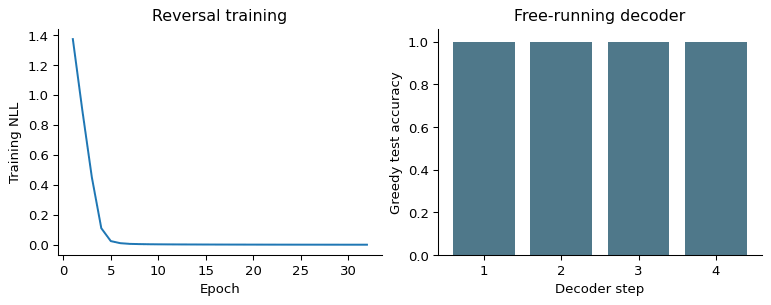

In [3]:
model.eval()
target = test.flip([1])
token = torch.full_like(test[:, :1], 5)
with torch.no_grad():
    logits = model(test, torch.cat((token, target[:, :-1]), dim=1))
    for _ in range(4):
        token = torch.cat((token, model(test, token)[:, -1].argmax(-1, keepdim=True)), dim=1)
greedy = token[:, 1:]
for_name = [("Teacher forced", logits.argmax(-1)), ("Greedy", greedy)]
report(
    ["Evaluation", "Strings", "Token accuracy", "Exact string accuracy"],
    [
        (
            name,
            len(test),
            (pred == target).float().mean().item(),
            (pred == target).all(1).float().mean().item(),
        )
        for name, pred in for_name
    ],
)
report(
    ["Input", "Expected", "Greedy prediction"],
    [
        tuple(" ".join(map(str, t.tolist())) for t in group)
        for group in zip(test[:4], target[:4], greedy[:4])
    ],
)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.1), layout="constrained")
axes[0].plot(range(1, len(curve) + 1), curve)
axes[0].set(xlabel="Epoch", ylabel="Training NLL", title="Reversal training")
axes[1].bar(range(1, 5), (greedy == target).float().mean(0), color="#4f788a")
axes[1].set(
    xlabel="Decoder step",
    ylabel="Greedy test accuracy",
    ylim=(0, 1.06),
    title="Free-running decoder",
)
plt.show()

## Interpreting the result

All 145 unseen strings were reversed exactly under greedy decoding. The test uses four-symbol strings drawn from the same five-symbol alphabet as training. Longer inputs require a different position table and a separate test.

Exact-string accuracy is more demanding than token accuracy. If the two decoding protocols disagree, inspect the first wrong symbol and its effect on later positions.

## Exercise

Test the trained network on strings with repeated symbols only and compare its errors with those on the rest of the test set.

## References

[Vaswani et al. (2017), Attention Is All You Need](https://arxiv.org/abs/1706.03762)